# 05 — Análisis, validación y storytelling

Fase 6 del proyecto. Aquí interpretamos los resultados, respondemos las preguntas clave, construimos la narrativa con los datos, proponemos decisiones basadas en evidencia y discutimos las limitaciones del análisis.

## 1. Interpretación de resultados e insights

Volvemos a las tres preguntas de negocio del [notebook 01, sección 2](01_comprension_problema.ipynb): cuánto invertir, cuándo estrenar y qué tipo de película hacer. Leemos juntas las pruebas del [notebook 03](03_hipotesis_pruebas.ipynb) y los indicadores del [notebook 04](04_kpis.ipynb), separando los hallazgos descriptivos de los resultados respaldados por una prueba estadística.

Esta sección interpreta la evidencia disponible. El desarrollo de la narrativa, las decisiones y la discusión general de limitaciones se construyen a partir de estos hallazgos en la siguiente sección.

### 1.1 Qué población estamos interpretando

La referencia principal son las películas de la **base financiera estrenadas desde 2000**: estrenadas, con presupuesto y recaudación reportados y sin montos menores a 10.000 USD. La vista de toda la base se usa como comparación de sensibilidad al periodo. El año final es el último estreno con información financiera válida, no el año actual.

| Evidencia | Fuente del proyecto | Cómo la usamos |
|---|---|---|
| Población, retorno y umbral de rentabilidad | `peliculas_variables.csv`; notebooks 02 y 03 | Seleccionar las mismas películas y conservar las definiciones |
| Seis KPIs generales y por segmento | `kpis_referencia.csv`; notebook 04, sección 2.7 | Recuperar los indicadores ya calculados y contrastar las proporciones con los datos |
| Significancia, efecto e intervalos | Notebook 03, secciones 2.1, 2.2 y 2.3 | Interpretar las pruebas existentes; no plantear pruebas nuevas |
| Participación de directores | `pelicula_director.csv`; página de géneros y talento | Contar películas únicas de directores con al menos cinco títulos en el periodo |

Los cálculos de esta sección aplican el periodo directamente sobre los CSV y se pueden ejecutar sin Power BI ni variables de otros kernels.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Funciona al ejecutar desde notebooks/ o desde la raíz del proyecto en VS Code.
insights_raiz = Path.cwd() if (Path.cwd() / "data/processed").is_dir() else Path.cwd().parent
insights_ruta = insights_raiz / "data/processed"
insights_peliculas = pd.read_csv(
    insights_ruta / "peliculas_variables.csv",
    parse_dates=["release_date"],
    dtype={"base_financiera": "boolean", "rentable": "boolean", "temporada_alta": "boolean"},
)
insights_referencia = pd.read_csv(insights_ruta / "kpis_referencia.csv")
insights_puente = pd.read_csv(insights_raiz / "data/model/pelicula_director.csv")
insights_anio_corte = 2000
insights_periodo = f"Desde {insights_anio_corte}"
insights_columnas_kpi = [
    "ROI mediano (%)", "% rentables", "% no recuperan presupuesto",
    "Presupuesto mediano (M USD)", "Recaudación total (M USD)", "Multiplicador típico (x)",
]

assert insights_peliculas["id"].is_unique
assert not insights_referencia.duplicated(["vista", "segmento", "periodo"]).any()
insights_finanzas = insights_peliculas.loc[insights_peliculas["base_financiera"].fillna(False)].copy()
insights_recientes = insights_finanzas.loc[insights_finanzas["anio"].ge(insights_anio_corte)].copy()
assert not insights_recientes.empty
assert insights_finanzas[["budget", "revenue", "multiplicador", "roi", "rentable", "temporada_alta"]].notna().all().all()
assert insights_finanzas[["budget", "revenue"]].ge(10_000).all().all()
np.testing.assert_allclose(insights_finanzas["multiplicador"], insights_finanzas["revenue"] / insights_finanzas["budget"])
assert insights_finanzas["rentable"].eq(insights_finanzas["multiplicador"].ge(2)).all()

insights_generales = (insights_referencia.loc[insights_referencia["vista"].eq("General")]
                      .set_index("periodo").loc[["Toda la base", insights_periodo]])
assert insights_generales.loc["Toda la base", "Películas"] == len(insights_finanzas)
assert insights_generales.loc[insights_periodo, "Películas"] == len(insights_recientes)
insights_linea_base = insights_generales.loc[insights_periodo]
print(f"Base financiera: {len(insights_finanzas):,} películas únicas.")
print(f"Referencia principal: {int(insights_recientes['anio'].min())}–{int(insights_recientes['anio'].max())}, "
      f"n = {len(insights_recientes):,}; sin género registrado: {insights_recientes['genero_agrupado'].isna().sum()}.")

Base financiera: 3,204 películas únicas.
Referencia principal: 2000–2016, n = 2,265; sin género registrado: 1.


### 1.2 La referencia cambia al mezclar épocas

Antes de comparar un género o una temporada, ponemos al lado los dos periodos. Los porcentajes están expresados de 0 a 100 y los montos en millones de USD nominales. La tabla conserva los cuatro decimales del archivo de referencia; el texto presenta las cifras aproximadas. El multiplicador típico es la **media geométrica**, mientras que el ROI mediano usa la mediana; son resúmenes distintos.

In [2]:
insights_generales[["Películas", *insights_columnas_kpi]].round(4)

,Películas,ROI mediano (%),% rentables,% no recuperan presupuesto,Presupuesto mediano (M USD),Recaudación total (M USD),Multiplicador típico (x)
periodo,,,,,,,
Toda la base,3204,130.5641,56.211,24.1885,25.515,391472.0840,2.0361
Desde 2000,2265,115.3030,53.245,25.6071,30.000,303605.7488,1.8050


**Lectura.** Para las 2.265 películas de 2000–2016, el ROI mediano es 115,30 %, frente a 130,56 % en toda la base. Los porcentajes de rentables son 53,25 % y 56,21 %, respectivamente. Mezclar las épocas ofrece una referencia de retorno más favorable que la del cine reciente de esta muestra.

Un ROI mediano de 115,30 % significa un multiplicador mediano de aproximadamente 2,15x. El multiplicador típico de 1,81x no lo contradice: la media del logaritmo y la mediana responden de forma distinta a la distribución de retornos. Ninguno de los dos predice el resultado de una película particular.

La diferencia entre periodos muestra sensibilidad a la composición de la muestra. No identifica por sí sola cuánto se debe a inflación, selección de películas antiguas u otros factores. La recaudación total de 303.605,75 M USD desde 2000 representa volumen acumulado de esta base, no ingresos anuales del mercado ni utilidad neta.

### 1.3 No recuperar el presupuesto y no llegar a 2x son situaciones diferentes

Los KPI02 y KPI03 no son complementarios. Entre recaudar una vez el presupuesto y recaudar el doble queda un grupo que supera el coste de producción en taquilla, pero no alcanza el criterio aproximado de rentabilidad del proyecto. Contamos las películas para separar esas tres situaciones.

In [3]:
insights_tramos = pd.Series(np.select(
    [insights_recientes["multiplicador"].lt(1), insights_recientes["multiplicador"].lt(2)],
    ["Taquilla < presupuesto", "Presupuesto ≤ taquilla < 2x"],
    default="Taquilla ≥ 2x presupuesto",
), index=insights_recientes.index)
insights_orden_tramos = ["Taquilla < presupuesto", "Presupuesto ≤ taquilla < 2x", "Taquilla ≥ 2x presupuesto"]
insights_recuperacion = insights_tramos.value_counts().reindex(insights_orden_tramos, fill_value=0).rename("Películas").to_frame()
insights_recuperacion["% de la base 2000–2016"] = insights_recuperacion["Películas"] / len(insights_recientes) * 100
assert insights_recuperacion["Películas"].sum() == len(insights_recientes)
np.testing.assert_allclose(
    insights_recuperacion.iloc[[0, 2]]["% de la base 2000–2016"].to_numpy(),
    insights_linea_base[["% no recuperan presupuesto", "% rentables"]].to_numpy(dtype=float),
    rtol=0, atol=0.000051,  # El CSV de referencia conserva cuatro decimales.
)
insights_recuperacion.round(2)

,Películas,% de la base 2000–2016
Taquilla < presupuesto,580,25.61
Presupuesto ≤ taquilla < 2x,479,21.15
Taquilla ≥ 2x presupuesto,1206,53.25


**Insight.** Desde 2000, el 25,61 % no recuperó el presupuesto en taquilla, el 21,15 % quedó entre 1x y menos de 2x y el 53,25 % llegó al umbral de 2x. Las pequeñas diferencias al sumar porcentajes vienen del redondeo.

El segundo grupo no se puede presentar como utilidad asegurada: la recaudación incluye dinero que no recibe la productora y no están registrados todos los costes. Tampoco llamamos pérdida neta al primer grupo; describimos exactamente lo que se observa: taquilla menor que presupuesto.

### 1.4 Pregunta 1: ¿más presupuesto mejora el retorno por cada dólar?

La prueba de Spearman del notebook 03, sección 2.1, da **ρ = −0,0001 y p = 0,996** en las 2.265 películas desde 2000. No se rechaza H0 con α = 0,05: no encontramos evidencia de una asociación monótona entre presupuesto y multiplicador. Esto no demuestra que el presupuesto sea irrelevante, ni descarta relaciones no monótonas.

Para leer el riesgo observado usamos los mismos cuartiles de presupuesto de esa prueba. Los cortes se calculan sobre el periodo completo y se mantienen fijos para esta comparación.

In [4]:
insights_cortes = insights_recientes["budget"].quantile([0, .25, .5, .75, 1]).to_numpy()
insights_etiquetas = [f"{a / 1e6:g} a {b / 1e6:g}" for a, b in zip(insights_cortes[:-1], insights_cortes[1:])]
insights_cuartiles = pd.cut(insights_recientes["budget"], insights_cortes,
                           labels=insights_etiquetas, include_lowest=True)
insights_presupuesto = (insights_recientes.assign(
    cuartil=insights_cuartiles,
    no_recupera=insights_recientes["multiplicador"].lt(1),
).groupby("cuartil", observed=True).agg(
    **{"Películas": ("id", "nunique"), "% no recuperan presupuesto": ("no_recupera", "mean"),
       "% rentables": ("rentable", "mean")}
))
insights_presupuesto[["% no recuperan presupuesto", "% rentables"]] *= 100
assert insights_presupuesto["Películas"].sum() == len(insights_recientes)
display(insights_presupuesto.rename_axis("Cuartil de presupuesto (M USD), 2000–2016").round(2))
insights_brecha_riesgo = (insights_presupuesto["% no recuperan presupuesto"].iloc[0]
                         - insights_presupuesto["% no recuperan presupuesto"].iloc[-1])
print(f"Brecha descriptiva del riesgo, cuartil más barato menos más caro: {insights_brecha_riesgo:.2f} puntos porcentuales.")

,Películas,% no recuperan presupuesto,% rentables
"Cuartil de presupuesto (M USD), 2000–2016",,,
0.015 a 15,639,31.61,55.09
15 a 30,525,28.19,48.38
30 a 62,536,26.31,48.51
62 a 380,565,15.75,60.18


Brecha descriptiva del riesgo, cuartil más barato menos más caro: 15.86 puntos porcentuales.


**Respuesta e insight.** Más presupuesto no aparece asociado con un aumento sistemático del retorno por dólar en el periodo reciente. Sin embargo, las películas del cuartil de hasta 15 M USD no recuperan su presupuesto en taquilla con mayor frecuencia que las del cuartil superior a 62 M: 31,61 % frente a 15,75 %, una brecha de 15,86 puntos porcentuales.

La segunda comparación es **descriptiva**. Spearman no prueba esas diferencias de proporciones. Por eso no concluimos que aumentar el presupuesto reduzca el riesgo ni que todos los rangos produzcan el mismo retorno. El hallazgo es que retorno relativo y frecuencia de no recuperación cuentan aspectos distintos de la inversión.

La correlación negativa de toda la base (ρ = −0,1368; p = 7,5 × 10⁻¹⁵) no se mantiene al restringir el periodo. Esa sensibilidad impide usar el resultado global como una regla general de que «cuanto más barata, mejor».

### 1.5 Pregunta 2: ¿la temporada alta se asocia con un mejor retorno?

La temporada alta reúne mayo, junio, julio, agosto, noviembre y diciembre, según la definición del notebook 03. La prueba de Welch compara el promedio de `log10(multiplicador)`, que al volver a la escala original se interpreta mediante la razón de medias geométricas.

In [5]:
insights_temporadas = (insights_referencia.loc[
    insights_referencia["vista"].eq("Temporada") & insights_referencia["periodo"].eq(insights_periodo)
].set_index("segmento").loc[["Temporada alta", "Resto del año"]])
assert insights_temporadas["Películas"].sum() == len(insights_recientes)
display(insights_temporadas[["Películas", "Multiplicador típico (x)", "% rentables", "% no recuperan presupuesto"]].round(2))
insights_razon_temporada = (insights_temporadas.loc["Temporada alta", "Multiplicador típico (x)"]
                           / insights_temporadas.loc["Resto del año", "Multiplicador típico (x)"])
print(f"Razón del multiplicador típico, alta / resto: {insights_razon_temporada:.2f}x.")

,Películas,Multiplicador típico (x),% rentables,% no recuperan presupuesto
segmento,,,,
Temporada alta,1092,1.95,57.14,22.16
Resto del año,1173,1.68,49.62,28.82


Razón del multiplicador típico, alta / resto: 1.16x.


**Respuesta e insight.** Desde 2000, la temporada alta tiene un multiplicador típico de 1,95x frente a 1,68x en el resto del año. La razón es **1,16x**, con IC del 95 % de **1,04 a 1,30** y **p = 0,008** en la prueba del notebook 03, sección 2.2. Hay evidencia de diferencia, aunque su magnitud es pequeña frente a la variación entre películas.

Ese 16 % aproximado se refiere al multiplicador típico; no equivale a 16 puntos porcentuales más de películas rentables. Los porcentajes observados de rentables son 57,14 % y 49,62 %, una diferencia descriptiva de unos 7,5 puntos. Welch no contrasta esas proporciones.

La revisión por cuartiles del notebook 03 concentra la evidencia en presupuestos de 30–62 M y superiores a 62 M USD, con razones de 1,28x y 1,24x y valores p de 0,002 y 0,009. En los dos cuartiles inferiores no se encontró evidencia suficiente de diferencia. Esto **no prueba que la temporada solo sirva para películas grandes**: las comparaciones por subgrupos son exploratorias y los intervalos de los grupos baratos permiten efectos en ambas direcciones.

Tampoco se identifica el efecto de cambiar una fecha de estreno. Los grupos pueden diferir en franquicias, distribución o promoción, aspectos que estas pruebas no controlan.

### 1.6 Pregunta 3: ¿qué nos dice el género sobre la rentabilidad?

Usamos el género principal agrupado, igual que la hipótesis 3. Una película de la cohorte reciente no tiene género y queda fuera de esta comparación, pero permanece en la referencia general de 2.265. La prueba y las comparaciones entre géneros trabajan con **2.264 películas**.

In [6]:
insights_generos = (insights_referencia.loc[
    insights_referencia["vista"].eq("Género agrupado") & insights_referencia["periodo"].eq(insights_periodo)
].set_index("segmento").sort_values("% rentables", ascending=False))
assert insights_generos["Películas"].sum() == insights_recientes["genero_agrupado"].notna().sum()
display(insights_generos[["Películas", "ROI mediano (%)", "% rentables", "% no recuperan presupuesto",
                         "Presupuesto mediano (M USD)"]].round(2))
insights_brecha_terror = insights_generos.loc["Horror", "% rentables"] - insights_linea_base["% rentables"]
insights_cuota_accion = (insights_generos.loc["Action", "Recaudación total (M USD)"]
                        / insights_linea_base["Recaudación total (M USD)"] * 100)
print(f"Terror frente a la referencia general reciente: +{insights_brecha_terror:.2f} puntos porcentuales de rentables.")
print(f"Acción: {insights_cuota_accion:.2f} % de la recaudación reciente de la base.")

,Películas,ROI mediano (%),% rentables,% no recuperan presupuesto,Presupuesto mediano (M USD)
segmento,,,,,
Horror,125,249.21,77.60,15.20,12.60
Animation,84,135.30,58.33,19.05,80.00
Adventure,185,123.44,57.30,20.54,85.00
Comedy,464,133.58,56.68,23.92,25.00
Fantasy,64,122.65,56.25,14.06,65.50
Science Fiction,49,157.12,55.10,16.33,75.00
Thriller,102,116.08,54.90,23.53,27.61
Drama,519,92.50,49.33,32.76,20.00
Romance,49,99.25,48.98,22.45,25.00


Terror frente a la referencia general reciente: +24.35 puntos porcentuales de rentables.
Acción: 24.12 % de la recaudación reciente de la base.


**Respuesta e insight.** La chi-cuadrado del notebook 03, sección 2.3, encuentra asociación entre género y rentabilidad: **χ² = 48,76, 11 gl, p = 1,0 × 10⁻⁶ y V de Cramér = 0,147** desde 2000. La asociación es estadísticamente significativa, pero débil.

Terror destaca en la descripción: 125 películas, 77,60 % de rentables, ROI mediano de 249,21 % y presupuesto mediano de 12,6 M USD. Su proporción de rentables está unos 24,35 puntos por encima de la referencia general reciente. Además, explica el 61,0 % del chi-cuadrado de ese periodo. Eso lo convierte en el principal componente del resultado global, no en una garantía para un proyecto nuevo.

La prueba sin terror da p = 0,069. No se rechaza H0 entre los otros géneros; esto no demuestra que sean iguales ni que se haya probado cada diferencia individual. La chi-cuadrado global tampoco es una prueba específica de cada pareja de géneros. La ventaja de terror en los dos cuartiles baratos se estudió después de observar el resultado principal y se interpreta como evidencia exploratoria de apoyo.

**Volumen y retorno se separan.** Acción concentra aproximadamente el 24,12 % de la recaudación de la cohorte reciente, pero tiene 47,57 % de rentables y ROI mediano de 87,90 %, por debajo de la referencia general. Ser un segmento de gran taquilla no implica rendir más por cada dólar invertido. El orden descriptivo de los demás géneros no se presenta como un ranking de diferencias estadísticamente probadas.

### 1.7 Cómo interpretar la vista de talento

La página de géneros y talento muestra directores con al menos cinco películas de la base financiera en el periodo seleccionado. Para leer su total hay que reunir las **películas únicas**, porque una película puede tener más de un director. El umbral se aplica al número de títulos de cada director en 2000–2016; no mide su carrera completa.

In [7]:
assert not insights_puente.duplicated(["pelicula_id", "director_id"]).any()
assert insights_puente["pelicula_id"].isin(insights_peliculas["id"]).all()
insights_creditos_recientes = insights_puente.loc[
    insights_puente["pelicula_id"].isin(insights_recientes["id"]) & insights_puente["director_id"].ne(0)
]
insights_titulos_director = insights_creditos_recientes.groupby("director_id")["pelicula_id"].nunique()
insights_directores_elegibles = insights_titulos_director.loc[insights_titulos_director.ge(5)].index
insights_ids_talento = insights_creditos_recientes.loc[
    insights_creditos_recientes["director_id"].isin(insights_directores_elegibles), "pelicula_id"
].unique()
insights_talento = insights_recientes.loc[insights_recientes["id"].isin(insights_ids_talento)]
assert insights_talento["id"].is_unique
insights_resumen_talento = pd.DataFrame([
    {"Grupo": "Base financiera 2000–2016", "Películas únicas": len(insights_recientes),
     "% rentables": insights_recientes["rentable"].mean() * 100},
    {"Grupo": "Películas de directores con al menos 5 títulos en la cohorte",
     "Películas únicas": len(insights_talento), "% rentables": insights_talento["rentable"].mean() * 100},
]).set_index("Grupo")
print(f"Directores con al menos cinco títulos: {len(insights_directores_elegibles)}.")
insights_resumen_talento.round(2)

Directores con al menos cinco títulos: 101.


,Películas únicas,% rentables
Grupo,,
Base financiera 2000–2016,2265,53.25
Películas de directores con al menos 5 títulos en la cohorte,603,64.18


**Insight descriptivo.** Los 101 directores que cumplen el criterio reúnen 603 películas únicas, con 64,18 % de rentables. El 53,25 % general incluye esas mismas películas: no son dos muestras independientes ni una comparación entre ese grupo y todos los directores restantes.

Este porcentaje no demuestra un efecto del director. Seleccionar personas con varios títulos ya favorece trayectorias observadas con continuidad, y la base no permite separar esa selección de presupuesto, género, distribución u otros factores. No se hizo una prueba de hipótesis sobre talento; por eso este hallazgo se presenta como contexto descriptivo y no como evidencia causal ni como evaluación de contratación.

### 1.8 A quién describen estos hallazgos

La composición por idioma ayuda a acotar la interpretación. Recuperamos los dos grupos que ya calculó el notebook 04, sin comparar por separado idiomas con muy pocos títulos.

In [8]:
insights_idiomas = (insights_referencia.loc[
    insights_referencia["vista"].eq("Idioma") & insights_referencia["periodo"].eq(insights_periodo)
].set_index("segmento"))
assert insights_idiomas["Películas"].sum() == len(insights_recientes)
display(insights_idiomas[["Películas", "% rentables", "% no recuperan presupuesto"]].round(2))
insights_porcentaje_ingles = insights_recientes["original_language"].eq("en").mean() * 100
print(f"Películas en inglés: {insights_porcentaje_ingles:.2f} % de la cohorte reciente.")

,Películas,% rentables,% no recuperan presupuesto
segmento,,,
Inglés (en),2159,53.45,25.24
Otros idiomas,106,49.06,33.02


Películas en inglés: 95.32 % de la cohorte reciente.


**Alcance de la lectura.** El inglés representa 2.159 de 2.265 películas (95,32 %). Las otras 106 combinan distintos idiomas y contextos de producción. Los resultados describen principalmente el cine en inglés con cifras reportadas; no permiten trasladar los porcentajes directamente al mercado colombiano ni atribuir al idioma las diferencias observadas.

La interpretación de épocas sigue el mismo criterio: la década de 2010 está incompleta y la taquilla nominal no permite inferir crecimiento real de la industria. Estas cautelas acotan las afirmaciones de esta sección; la discusión general de limitaciones se desarrolla junto con la narrativa y las decisiones del proyecto.

### 1.9 Hallazgos que conectan las tres preguntas

| Pregunta | Evidencia principal en 2000–2016 | Interpretación que sí sostiene el análisis |
|---|---|---|
| ¿Más presupuesto mejora el retorno por dólar? | H1: n = 2.265; ρ = −0,0001; p = 0,996. KPI03: 31,61 % frente a 15,75 % de no recuperación en los cuartiles extremos | No hay evidencia de una asociación monótona. La frecuencia de no recuperación difiere descriptivamente; retorno relativo y riesgo observado no son equivalentes |
| ¿La temporada alta se asocia con mejor retorno? | H2: n = 1.092 / 1.173; razón de multiplicadores típicos = 1,16x; IC 95 % = 1,04–1,30; p = 0,008 | Hay una asociación de magnitud limitada. Los subgrupos no permiten afirmar que cambiar la fecha causará una mejora ni que la temporada sea irrelevante para producciones pequeñas |
| ¿El género se relaciona con llegar al umbral de 2x? | H3: n = 2.264; p = 1,0 × 10⁻⁶; V = 0,147. KPI02 de terror: 77,60 % en 125 películas | La asociación global es débil y terror explica su mayor parte. Los datos no prueban un ranking completo de géneros ni garantizan la rentabilidad de una película nueva |

Las tres preguntas se complementan: presupuesto, calendario y género describen dimensiones diferentes del resultado. La significancia estadística no reemplaza la magnitud del efecto, el tamaño de muestra ni el criterio de rentabilidad. La siguiente sección puede construir la narrativa y las decisiones a partir de esta evidencia, conservando la distinción entre asociación, descripción y causalidad.

## 2. Storytelling, decisiones y limitaciones

En la sección 1 quedó la evidencia. Aquí la convertimos en una historia y en decisiones concretas para la productora del notebook 01. Primero contamos la historia completa en tres partes. Después miramos los datos desde donde la productora realmente se mueve, que son las películas de bajo presupuesto, y respondemos una duda que dejó la hipótesis 1: si conviene hacer una película grande o varias pequeñas. Cerramos con las decisiones, cada una con su evidencia, y con las limitaciones.

### 2.1 La historia en tres partes

**El problema.** Una productora independiente tiene capital para una película mediana, unos 30 millones de dólares, o para varias pequeñas, y no se puede dar el lujo de perderlo. Tiene que decidir cuánto invertir por película, cuándo estrenar y qué tipo de película hacer. Para responder usamos las 2.265 películas de TMDB estrenadas desde 2000 con presupuesto y recaudación confiables.

**Lo que encontramos.** La primera sorpresa fue que la respuesta cambia según la época que se mire. Con toda la base, las películas baratas parecían rendir más, pero esa correlación venía de los clásicos anteriores a 2000; en el cine reciente desaparece. Lo que sí cambia con el presupuesto es el riesgo: casi un tercio de las películas de hasta 15 millones no recupera su costo en taquilla, contra una de cada seis de las de más de 62 millones. La temporada alta se asocia con un retorno un 16 % mayor, pero la evidencia se concentra en las películas de más de 30 millones. Y entre los géneros, uno solo se despega: el terror, rentable en el 77,6 % de los casos y con un presupuesto mediano de 12,6 millones.

**La decisión.** Para una productora pequeña, la pregunta no es cómo conseguir una película que rinda mucho, sino cómo no quedarse sin capital. Los datos apuntan a tres cosas: repartir la inversión en varias películas pequeñas, darle prioridad al terror y no pagar de más por una fecha de temporada alta. Las secciones siguientes muestran de dónde sale cada una.

### 2.2 El terreno de la productora: películas de hasta 15 millones

Los resultados generales mezclan producciones de 1 y de 300 millones. Una productora con capital limitado va a moverse en el cuartil más barato, el de hasta 15 millones, así que volvemos a mirar ahí lo que encontramos en las hipótesis 2 y 3: el género y la temporada. Usamos los mismos KPIs del notebook 04, el porcentaje de rentables (KPI02) y el de películas que no recuperan su presupuesto (KPI03).

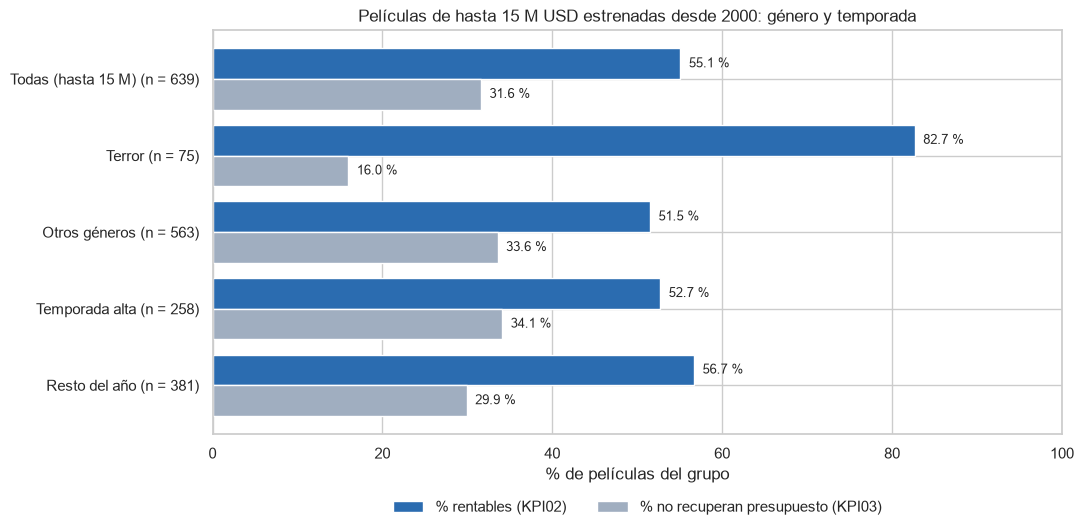

,Películas,% rentables,% no recuperan presupuesto,Presupuesto mediano (M USD)
Todas (hasta 15 M),639,55.1,31.6,7.5
Terror,75,82.7,16.0,5.0
Otros géneros,563,51.5,33.6,8.0
Temporada alta,258,52.7,34.1,8.0
Resto del año,381,56.7,29.9,7.0


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
AZUL, GRIS = "#2b6cb0", "#a0aec0"
historia_tope_pequenas = 15e6

historia_pequenas = insights_recientes.loc[insights_recientes["budget"].le(historia_tope_pequenas)]
historia_grupos = {
    "Todas (hasta 15 M)": historia_pequenas,
    "Terror": historia_pequenas.loc[historia_pequenas["genero_agrupado"].eq("Horror")],
    "Otros géneros": historia_pequenas.loc[historia_pequenas["genero_agrupado"].notna()
                                           & historia_pequenas["genero_agrupado"].ne("Horror")],
    "Temporada alta": historia_pequenas.loc[historia_pequenas["temporada_alta"].eq(True)],
    "Resto del año": historia_pequenas.loc[historia_pequenas["temporada_alta"].eq(False)],
}
historia_terreno = pd.DataFrame({
    grupo: {
        "Películas": datos["id"].nunique(),
        "% rentables": datos["rentable"].mean() * 100,
        "% no recuperan presupuesto": datos["multiplicador"].lt(1).mean() * 100,
        "Presupuesto mediano (M USD)": datos["budget"].median() / 1e6,
    }
    for grupo, datos in historia_grupos.items()
}).T.astype({"Películas": int})

fig, ax = plt.subplots(figsize=(11, 5.5))
posiciones = np.arange(len(historia_terreno))
ax.barh(posiciones - 0.2, historia_terreno["% rentables"], height=0.4, color=AZUL, label="% rentables (KPI02)")
ax.barh(posiciones + 0.2, historia_terreno["% no recuperan presupuesto"], height=0.4, color=GRIS,
        label="% no recuperan presupuesto (KPI03)")
for y, (rentables, no_recuperan) in enumerate(zip(historia_terreno["% rentables"],
                                                   historia_terreno["% no recuperan presupuesto"])):
    ax.text(rentables + 1, y - 0.2, f"{rentables:.1f} %", va="center", fontsize=9)
    ax.text(no_recuperan + 1, y + 0.2, f"{no_recuperan:.1f} %", va="center", fontsize=9)
ax.set_yticks(posiciones, [f"{grupo} (n = {n})" for grupo, n in historia_terreno["Películas"].items()])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title(f"Películas de hasta 15 M USD estrenadas desde {insights_anio_corte}: género y temporada")
ax.set_xlabel("% de películas del grupo")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

historia_terreno.round(1)

**¿Qué vemos?** En el terreno de la productora, el género pesa mucho más que la fecha.

- **El terror cambia el panorama.** De las 75 películas de terror de hasta 15 millones, el 82,7 % fue rentable y solo el 16,0 % no recuperó su presupuesto. En los demás géneros del mismo rango, esos valores son 51,5 % y 33,6 %. Esta diferencia es la que el notebook 03 probó con una chi-cuadrado de 2 × 2 (p = 3,5 × 10⁻⁷), como revisión del resultado principal de la hipótesis 3.
- **La temporada alta no ayuda a las películas pequeñas.** En este rango, las películas de temporada alta tienen 52,7 % de rentables y 34,1 % que no recupera, un poco peor que el resto del año (56,7 % y 29,9 %). Coincide con la hipótesis 2: en el cuartil más barato la prueba no encontró evidencia de diferencia (0,89 veces, p = 0,470). Como advirtió la sección 1.5, esto tampoco prueba que la temporada les haga daño; el intervalo es muy ancho.

Estas comparaciones son descriptivas, salvo la del terror, que tiene su prueba en el notebook 03.

### 2.3 ¿Una película de 30 millones o cuatro pequeñas?

La hipótesis 1 dejó una pregunta abierta. El retorno típico no cambia con el presupuesto, pero las películas pequeñas fallan más seguido: el 31,6 % no recupera lo que costó. Entonces, ¿es mejor hacer una sola película de unos 30 millones o repartir ese capital en cuatro películas de 5 a 10 millones?

Para responder simulamos carteras de películas con los datos históricos desde 2000. Cada cartera se arma sacando películas al azar del grupo de presupuesto correspondiente, con reemplazo, y se calcula su multiplicador como el total recaudado dividido entre el total invertido. Repetimos el sorteo 10.000 veces para cada opción y contamos en cuántas carteras la taquilla no alcanza a cubrir lo invertido. Esta técnica de remuestreo **no está en las guías del curso**: la usamos como un ejercicio descriptivo para ilustrar el riesgo, no como una prueba de hipótesis.

Supuesto clave: los resultados de las películas de una misma cartera son independientes entre sí, como si fueran sorteos separados de la historia.

Películas de 25 a 35 M USD: 362 | de 5 a 10 M USD: 238


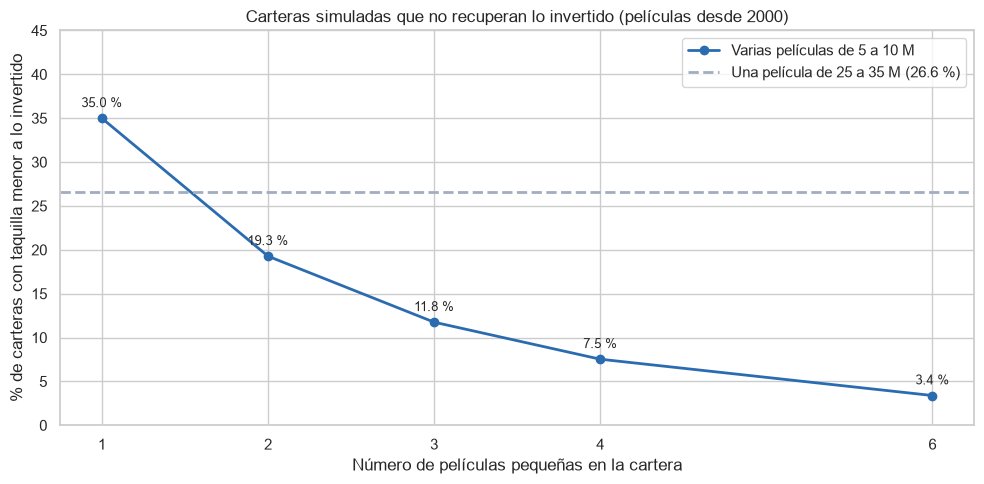

,% carteras que no recuperan lo invertido,% carteras que llegan a 2x,Multiplicador mediano de la cartera
1 película de 25 a 35 M,26.55,48.90,1.97
1 de 5 a 10 M,34.99,50.34,2.05
2 de 5 a 10 M,19.27,61.83,2.80
3 de 5 a 10 M,11.75,68.32,3.11
4 de 5 a 10 M,7.53,74.40,3.37
6 de 5 a 10 M,3.39,81.78,3.72


Sensibilidad sin el 5 % de mayores éxitos (multiplicador > 10.0x):


,% carteras que no recuperan lo invertido,% carteras que llegan a 2x,Multiplicador mediano de la cartera
1 película de 25 a 35 M,27.74,47.82,1.90
4 de 5 a 10 M,12.01,58.73,2.26


In [10]:
historia_rng = np.random.default_rng(2026)  # semilla fija para que el resultado se pueda repetir
historia_simulaciones = 10_000


def historia_cartera(grupo, peliculas, n=historia_simulaciones):
    # Arma n carteras de `peliculas` títulos sacados al azar (con reemplazo) del grupo histórico
    filas = historia_rng.integers(0, len(grupo), size=(n, peliculas))
    invertido = grupo["budget"].to_numpy()[filas].sum(axis=1)
    recaudado = grupo["revenue"].to_numpy()[filas].sum(axis=1)
    return recaudado / invertido


def historia_resumen(multiplicadores):
    return {
        "% carteras que no recuperan lo invertido": (multiplicadores < 1).mean() * 100,
        "% carteras que llegan a 2x": (multiplicadores >= 2).mean() * 100,
        "Multiplicador mediano de la cartera": np.median(multiplicadores),
    }


historia_grandes = insights_recientes.loc[insights_recientes["budget"].between(25e6, 35e6)]
historia_chicas = insights_recientes.loc[insights_recientes["budget"].between(5e6, 10e6)]
print(f"Películas de 25 a 35 M USD: {len(historia_grandes)} | de 5 a 10 M USD: {len(historia_chicas)}")

historia_opciones = {"1 película de 25 a 35 M": historia_resumen(historia_cartera(historia_grandes, 1))}
for cantidad in [1, 2, 3, 4, 6]:
    historia_opciones[f"{cantidad} de 5 a 10 M"] = historia_resumen(historia_cartera(historia_chicas, cantidad))
historia_carteras = pd.DataFrame(historia_opciones).T

# Sensibilidad: sin el 5 % de películas con mayor multiplicador (los grandes éxitos)
historia_tope_exito = insights_recientes["multiplicador"].quantile(0.95)
historia_sensibilidad = pd.DataFrame({
    "1 película de 25 a 35 M": historia_resumen(historia_cartera(
        historia_grandes.loc[historia_grandes["multiplicador"].le(historia_tope_exito)], 1)),
    "4 de 5 a 10 M": historia_resumen(historia_cartera(
        historia_chicas.loc[historia_chicas["multiplicador"].le(historia_tope_exito)], 4)),
}).T

riesgo_grande = historia_carteras.loc["1 película de 25 a 35 M", "% carteras que no recuperan lo invertido"]
riesgo_chicas = historia_carteras.drop(index="1 película de 25 a 35 M")["% carteras que no recuperan lo invertido"]
cantidades = [int(nombre.split()[0]) for nombre in riesgo_chicas.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(cantidades, riesgo_chicas, marker="o", linewidth=2, color=AZUL, label="Varias películas de 5 a 10 M")
for x, valor in zip(cantidades, riesgo_chicas):
    ax.annotate(f"{valor:.1f} %", (x, valor), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.axhline(riesgo_grande, color=GRIS, linestyle="--", linewidth=2,
           label=f"Una película de 25 a 35 M ({riesgo_grande:.1f} %)")
ax.set_xticks(cantidades)
ax.set_ylim(0, 45)
ax.set_title(f"Carteras simuladas que no recuperan lo invertido (películas desde {insights_anio_corte})")
ax.set_xlabel("Número de películas pequeñas en la cartera")
ax.set_ylabel("% de carteras con taquilla menor a lo invertido")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

display(historia_carteras.round(2))
print(f"Sensibilidad sin el 5 % de mayores éxitos (multiplicador > {historia_tope_exito:.1f}x):")
historia_sensibilidad.round(2)

**¿Qué vemos?** Repartir el capital reduce mucho el riesgo de perderlo.

- **Una sola película de 25 a 35 millones** no recupera lo invertido en el 26,6 % de las simulaciones. Una sola película pequeña es todavía más riesgosa (35,0 %): una película sola siempre es una apuesta.
- **Con cuatro películas de 5 a 10 millones**, por un total parecido, la cartera no recupera lo invertido solo en el 7,5 % de los casos, y llega a 2x en el 74,4 %. La gráfica muestra cómo el riesgo cae con cada película que se agrega: el fracaso de una lo compensa el éxito de otra.
- **El resultado aguanta sin los grandes éxitos.** Si quitamos el 5 % de películas con mayor multiplicador, que podrían inflar el resultado de las baratas, la cartera de cuatro sigue perdiendo plata con mucha menos frecuencia que la película única (12,0 % contra 27,7 %).

Hay que leer esto con cuidado. La simulación supone que las películas de una cartera son independientes, y en la práctica una misma productora comparte equipo, estilo y distribución. Además, el sesgo de selección favorece a las películas baratas: las pequeñas que fracasaron tienen menos probabilidad de aparecer en TMDB. Aun con esas reservas, la dirección del resultado es clara y coincide con lo que mostró el KPI03 por cuartil: con poco capital, diversificar protege más que concentrar.

### 2.4 Decisiones para la productora

Cada decisión indica qué tipo de evidencia la respalda: una **prueba** del notebook 03, una **comparación descriptiva** o la **simulación** de la sección 2.3. Al final, el KPI con el que se puede seguir en el dashboard.

| # | Decisión | Evidencia | Tipo | KPI para seguirla |
|---|---|---|---|---|
| 1 | **Repartir el capital en varias películas pequeñas** en vez de apostarlo a una sola | Desde 2000 no hay correlación entre presupuesto y retorno (ρ = −0,0001, p = 0,996), pero las de hasta 15 M fallan más (31,6 % contra 15,8 %). Con cuatro películas pequeñas, la cartera no recupera lo invertido en el 7,5 % de las simulaciones, contra 26,6 % con una sola | Prueba + descriptiva + simulación | KPI03 por rango de presupuesto (página de desempeño comercial) |
| 2 | **Darle prioridad al terror** dentro del bajo presupuesto | Asociación entre género y rentabilidad (χ² = 48,76, p = 1,0 × 10⁻⁶), explicada casi toda por terror. Hasta 15 M: 82,7 % de rentables contra 51,5 % de los demás géneros (p = 3,5 × 10⁻⁷) | Prueba | KPI02 y KPI04 por género (página de géneros) |
| 3 | **No pagar de más por una fecha de temporada alta** si la película es pequeña; si algún día produce por encima de 30 M, sí vale la pena buscarla | Temporada alta: 1,16 veces más retorno (IC 95 %: 1,04 a 1,30; p = 0,008), concentrado en las de más de 30 M (1,28x y 1,24x). Hasta 15 M no hubo evidencia de ventaja (0,89x, p = 0,470) | Prueba + revisión por subgrupos | KPI06 por temporada |
| 4 | **Medir el éxito por retorno y riesgo, no por recaudación** | Acción concentra el 24,1 % de la taquilla desde 2000, pero su ROI mediano (87,9 %) queda por debajo del total (115,3 %) | Descriptiva | KPI01 y KPI03 antes que KPI05 |

**Lo que no recomendamos**, aunque los datos parecieran decirlo a primera vista:

- **«Hacer películas baratas porque rinden más».** Esa conclusión sale de mezclar épocas. Con el cine reciente no hay evidencia de que las baratas rindan más por dólar; solo de que fallan más seguido.
- **«Escoger el género que más recauda».** Acción y aventura mueven más plata, pero eso refleja el tamaño de sus presupuestos, no su rendimiento.
- **«Mover la película a julio para que rinda más».** La temporada alta se asocia con más retorno, pero los estudios guardan esas fechas para sus apuestas más fuertes. No probamos que cambiar la fecha cause la mejora.

### 2.5 Limitaciones

Ninguna de estas limitaciones invalida las decisiones, pero sí marca hasta dónde llegan.

| Limitación | Qué afecta | Cómo la manejamos |
|---|---|---|
| **Asociación, no causalidad.** Son datos observados, no un experimento | Las tres hipótesis. No podemos decir que cambiar el presupuesto, la fecha o el género cause el resultado | Lo decimos en cada conclusión y separamos asociación, descripción y causa |
| **Sesgo de selección.** Solo hay películas que reportaron cifras, sobre todo las comerciales | Todos los porcentajes; favorece a las películas baratas, cuyos fracasos se reportan menos | Lo tenemos en cuenta al interpretar el riesgo de las pequeñas y la simulación, que pueden ser más optimistas de lo real |
| **Dólares nominales.** Sin ajuste por inflación | Comparaciones de presupuesto y recaudación entre épocas | Trabajamos con las películas desde 2000; el multiplicador casi no se afecta porque presupuesto y recaudación son del mismo año |
| **«Rentable» = 2x es una aproximación** | KPI02, hipótesis 3 y el 2x de la simulación | Lo dejamos explícito y mostramos también el porcentaje que no recupera el presupuesto (1x) |
| **Taquilla no es utilidad neta.** Faltan publicidad, comisión de salas y otros ingresos | Todos los montos | Hablamos de taquilla frente a presupuesto, nunca de ganancia contable |
| **Casi todo es cine en inglés** (95,3 % desde 2000) | Trasladar los resultados a otros mercados, como el colombiano | Lo declaramos como alcance: los resultados describen cine en inglés con cifras reportadas |
| **Fecha de TMDB.** Puede ser un festival o un estreno en otro país | La clasificación de temporada alta | Lo mencionamos en la hipótesis 2; algunas películas pueden estar en el grupo que no era |
| **La década de 2010 está incompleta** (hasta 2016 en la base financiera) | Las comparaciones por década | No sacamos conclusiones de la diferencia entre 2000 y 2010 |
| **Pruebas por subgrupos y simulación son exploratorias** | La recomendación de temporada para películas grandes y la de diversificar | Las presentamos como apoyo de las pruebas principales, no como hipótesis nuevas |

### 2.6 Conclusión

Empezamos con una pregunta de negocio: en qué películas debería invertir una productora con poco capital. La respuesta del análisis es que, para ella, **el riesgo importa más que el retorno**. Más presupuesto no hace que una película rinda más por dólar, pero una sola película pequeña falla casi una de cada tres veces. Por eso la mejor protección es repartir el capital en varias producciones, darle prioridad al terror, que en ese rango es rentable el 82,7 % de las veces, y no gastar de más en fechas de estreno que, para películas pequeñas, no mostraron ventaja.

Lo más valioso del proceso fue aprender a desconfiar del primer resultado. La correlación negativa entre presupuesto y retorno parecía una conclusión clara, y resultó ser un efecto de mezclar épocas. Revisar cada hallazgo por periodo, por tamaño de película y por magnitud del efecto, y no solo por su valor p, cambió las recomendaciones finales. Todo esto se puede seguir en el dashboard de Power BI con los mismos seis KPIs que calculamos en el notebook 04.